# Is the sample fit to validate? Leakage screens and data quality


**Question:** Can a validator trust any performance number computed on this sample, or does a feature carry the default flag before the model is even tested?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 04 of topic 01 (the battery and the lights) helps, no other topic is needed
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- say why a validator checks the sample before any model test, and what a leak does to a performance number;
- run the four leakage screens of the engine (temporal order, the single-feature AUC, the entity overlap and the resemblance AUC) and read each against its rule or cut point;
- count the five data-quality checks (completeness, validity, uniqueness, consistency and timeliness) and turn them into a light;
- read the committed leakage variant of case C20, where a leaking feature was planted in a real model and the screen caught it, and say what the screen does not prove.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ml import dataquality as dq
from riskvalidation.ml import leakage, plants
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import ml as vml

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red"}
SCREEN = {"temporal": "temporal", "single": "single", "overlap": "overlap", "resemblance": "resemblance"}
CHECK_NAMES = ["completeness", "validity", "uniqueness", "consistency", "timeliness"]

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Two sources, both small and both with a known answer.

- **The engine's planted-defect generators** (`riskvalidation.ml.plants`): a logistic portfolio of obligors with three honest features and, optionally, a fourth column that leaks the default flag. They are synthetic, generated from a seed, and the truth is known exactly, so a screen can be checked against it. No third-party data and no licence class apply.
- **The committed leakage variant of case C20** (`data/derived/C20/leakage-planted.json`; owner: this repository). It validates a LightGBM model on the Taiwan credit-card data (UCI, CC BY 4.0, class mirror-allowed) in which the pipeline planted a feature `future_status_code` that holds the default flag plus a little noise, dated after the observation date. It was baked with the engine version printed in the next cell, and this notebook never re-fits that model: it reads the rows the pipeline wrote.

The first cell opens the committed variant and prints what it says.

In [2]:
# Open the committed variant: the engine that baked it, the planted feature and the screen values
path = ROOT / "data" / "derived" / "C20" / "leakage-planted.json"
variant = json.loads(path.read_text(encoding="utf-8"))
out = variant["outputs"]
screen = out["screen"]
perf = out["performance"]
print("baked with riskvalidation", variant["provenance"]["riskvalidation_version"])
print("planted feature:", out["planted_feature"], "| caught:", "yes" if out["caught"] else "no")
print("feature values dated after the observation:", screen["temporal_order"]["violations"])
largest = screen["single_feature_auc"]
print(
    "largest single-feature AUC:",
    round(largest["max_auc"], 4),
    "| suspect:",
    "yes" if largest["suspect"] else "no",
)
print("entity overlap share:", screen["entity_overlap"]["share"])
print("resemblance AUC:", round(screen["resemblance_auc"], 4))
print(
    "AUC on the development sample:",
    round(perf["development_auc"], 4),
    "| AUC at decision time:",
    round(perf["decision_time_auc"], 4),
)

baked with riskvalidation 1.0.1
planted feature: future_status_code | caught: yes
feature values dated after the observation: 9000
largest single-feature AUC: 0.9998 | suspect: yes
entity overlap share: 0.0
resemblance AUC: 0.4932
AUC on the development sample: 0.9997 | AUC at decision time: 0.5028


## Method

A validation test is only as good as the sample it reads. If a feature carries the answer, every performance number that follows is flattering and tells nothing about the model in use. The engine's screens are **conventions, not regulatory thresholds**: no supervisory text prescribes them (the research dossier on model risk marks them so), they are the checks a validator runs because they are cheap and they catch the common failures. Their cut points are named parameters of the policy.

### Step 1: temporal order

A feature must be known at the observation date. The screen counts the feature values dated **after** the observation date of their row; a missing date is not a violation and a date equal to the observation date is not one either. The rule has no cut point: one violation is a leak. The next cell builds three rows by hand, two of whose feature dates fall after their observation date, and counts.

In [3]:
# Three rows by hand: two feature dates fall after their observation date
observation = np.array(["2024-01-31", "2024-02-29", "2024-03-31"], dtype="datetime64[D]")
feature_dates = np.array(
    [["2024-01-15", "2024-02-01"], ["2024-03-05", "2024-02-20"], ["2024-03-31", "2024-03-30"]],
    dtype="datetime64[D]",
)
print("violations:", leakage.temporal_order_violations(feature_dates, observation))
# A missing date is not a violation, and neither is a date equal to the observation date
with_gaps = feature_dates.copy()
with_gaps[1, 0] = np.datetime64("NaT")
print("violations with the late date missing:", leakage.temporal_order_violations(with_gaps, observation))

violations: 2
violations with the late date missing: 1


### Step 2: the single-feature AUC

A feature that ranks the defaulters almost perfectly **on its own** is a leakage suspect: real credit information is rarely that strong. For each column $j$ the engine computes the AUC of the column against the default flag (the engine's own `disc_auc`) and keeps the distance from chance:

$$A_j = \max\bigl(\mathrm{AUC}_j,\; 1 - \mathrm{AUC}_j\bigr), \qquad \text{suspect if } \max_j A_j > 0.95 .$$

The max with $1-\mathrm{AUC}$ catches a leak that ranks the wrong way round. On the engine's plant the leak column is $y \cdot s + N(0,1)$ with strength $s$, so its AUC is known exactly, $\Phi(s/\sqrt{2})$ (the binormal AUC; the engine's `LeakPlant.truth()` returns it). The next cell draws one clean sample (strength 0) and one leaky sample (strength 3) from the same seed, and prints the AUC of every column.

In [4]:
# Draw a clean and a leaky sample of 2,000 obligors and print the AUC of every column
samples = {}
for label, strength in (("clean", 0.0), ("leaky", 3.0)):
    plant = plants.LeakPlant(n=2000, leak_strength=strength, seed=7)
    draw = plant.sample()
    samples[label] = (draw["X"], draw["y"], plant.truth())
    aucs = [float(disc.disc_auc(draw["X"][:, j], draw["y"]).metric) for j in range(draw["X"].shape[1])]
    print(f"{label:9s} AUC per column:", [round(a, 4) for a in aucs])
    print(f"{'':9s} exact AUC of the leak column:", round(plant.truth()["leak_auc"], 4))

clean     AUC per column: [0.7454, 0.6972, 0.674, 0.479]
          exact AUC of the leak column: 0.5
leaky     AUC per column: [0.7454, 0.6972, 0.674, 0.9818]
          exact AUC of the leak column: 0.9831


The engine function `single_feature_auc` does the same in one call, folds the distance from chance and compares it with the cut point. The next cell calls it on both samples.

In [5]:
# The engine screen: the largest distance from chance over the columns, its column and the suspect flag
single = {}
for label, (X, y, truth) in samples.items():
    single[label] = leakage.single_feature_auc(X, y)
    found = single[label]
    flag = "yes" if found.suspect else "no"
    print(f"{label:9s} AUC {found.max_auc:.4f} | column {found.feature} | suspect: {flag}", end=" ")
    print("| true leak column:", truth["leak_column"])

clean     AUC 0.7454 | column 0 | suspect: no | true leak column: 3
leaky     AUC 0.9818 | column 3 | suspect: yes | true leak column: 3


### Step 3: the entity overlap

When the same entity (a client, a loan) is in the training and in the test slice, the test slice is no longer new: the model has seen the obligor. The share of distinct test entities that also appear in training is

$$\text{overlap} = \frac{|\text{test ids} \cap \text{train ids}|}{|\text{test ids}|},$$

and, like the temporal order, it is a rule: any overlap above zero trips the screen. The next cell uses identifiers written in the cell.

In [6]:
# Identifiers by hand: one test client is also in the training slice
train_ids = ["C001", "C002", "C003", "C004"]
test_ids = ["C004", "C005", "C006"]
print("overlap share:", round(leakage.entity_overlap(train_ids, test_ids), 4))
print("overlap share with a clean split:", leakage.entity_overlap(train_ids, ["C005", "C006"]))

overlap share: 0.3333
overlap share with a clean split: 0.0


### Step 4: the resemblance AUC (adversarial validation)

A leak in time shows up as a difference between the development rows and the out-of-time rows. The resemblance screen trains a classifier to tell development rows (class 0) from out-of-time rows (class 1) and reads its **cross-fitted** AUC, each row scored by a fold that did not train on it. If the two samples come from one population the classifier cannot tell them apart and the AUC is near $0.5$; the screen trips above $0.70$ (a convention). The classifier is the engine core's ridge logistic fit with five folds, and the AUC carries the ECB variance of the AUC (`auc_with_variance`). The idea follows the `sample_similarity` check of probatus (see the references).

The engine has a covariate-shift plant with a development sample and an evaluation sample; a shift of 0 standard deviations leaves them alike, a shift of 1.5 moves a quarter of the evaluation rows. The next cell screens both.

In [7]:
# Screen two covariate-shift plants: no shift, and a shift of 1.5 standard deviations on two features
resemblance = {}
for label, shift in (("no shift", 0.0), ("shifted", 1.5)):
    draw = plants.CovariateShiftPlant(n=1000, shift=shift, features=[0, 1], seed=3).sample()
    resemblance[label] = leakage.resemblance_auc(draw["X_dev"], draw["X_eval"], seed=1)
    r = resemblance[label]
    print(f"{label:22s} AUC {r.auc:.4f} | standard deviation {r.variance**0.5:.4f} | n {r.n}")

no shift               AUC 0.5058 | standard deviation 0.0129 | n 2000
shifted                AUC 0.6109 | standard deviation 0.0125 | n 2000


### Step 5: the four screens as one test

`leakage_screen` takes the four values and reads each against its key of the policy: the temporal order and the overlap are rules, the single-feature AUC and the resemblance AUC have cut points. The light is the worst of the four; `statistic` is how many screens tripped; `extras["screens"]` holds each value and its light. The next cell screens the clean and the leaky sample (with the resemblance of the no-shift plant for both) and prints the four values of each.

In [8]:
# One TestResult per sample: the four screens combined under the packaged policy
screened = {}
for label in samples:
    screened[label] = vml.leakage_screen("demo-model", 0, single[label], 0.0, resemblance["no shift"])
    result = screened[label]
    print(f"{label:9s} light: {LIGHT[result.light.value]} | screens tripped: {int(result.statistic)}")
    for name, s in result.extras["screens"].items():
        print(f"    {SCREEN[name]:12s} value {s['value']:.4f} light: {LIGHT[s['light']]}")

clean     light: green | screens tripped: 0
    temporal     value 0.0000 light: green
    single       value 0.7454 light: green
    overlap      value 0.0000 light: green
    resemblance  value 0.5058 light: green
leaky     light: red | screens tripped: 1
    temporal     value 0.0000 light: green
    single       value 0.9818 light: red
    overlap      value 0.0000 light: green
    resemblance  value 0.5058 light: green


### Step 6: data quality as counted checks

Leakage asks whether the answer is in the features. Data quality asks whether the features are what they claim to be. The engine counts five kinds of failure and returns each as a `DataQualityCount` (`n_checked`, `n_failed`, `share_ok`):

| Check | What fails | Engine function |
|---|---|---|
| Completeness | a cell that is NaN | `dq_completeness` |
| Validity | a non-missing cell outside its declared range | `dq_validity` |
| Uniqueness | an identifier that repeats | `dq_uniqueness` |
| Consistency | two views of the same field that disagree | `dq_consistency` |
| Timeliness | a record older than its maximum age at the as-of date | `dq_timeliness` |

The data-quality test takes the counts and reads the **largest share of failed checks** against the policy: green below 1%, amber from 1%, red from 5% (conventions, no dossier value). The next cell plants a small table with one defect of each kind.

In [9]:
# A table of ten obligors with one planted defect of each kind: gap, range, repeat, view, date
table = np.array(
    [
        [0.31, 12.0],
        [0.25, 18.0],
        [np.nan, 20.0],
        [0.40, 15.0],
        [1.70, 22.0],
        [0.10, 30.0],
        [0.55, 11.0],
        [0.62, 14.0],
        [0.48, 19.0],
        [0.27, 25.0],
    ]
)
ids = ["L01", "L02", "L03", "L04", "L05", "L06", "L07", "L08", "L02", "L10"]
status_a = ["open"] * 9 + ["closed"]
status_b = ["open"] * 9 + ["open"]
statement_dates = ["2025-12-31"] * 9 + ["2022-12-31"]
lo, hi = np.array([0.0, 0.0]), np.array([1.0, 60.0])
counts = [
    dq.dq_completeness(table),
    dq.dq_validity(table, lo=lo, hi=hi),
    dq.dq_uniqueness(ids),
    dq.dq_consistency(status_a, status_b),
    dq.dq_timeliness(statement_dates, as_of="2026-06-30", max_age_days=548),
]
for kind, c in zip(CHECK_NAMES, counts):
    share = c.n_failed / c.n_checked
    print(f"{kind:13s} checked {c.n_checked:3d} failed {c.n_failed:2d} share failed {share:.4f}")
print("missing cells per column:", counts[0].by_column)

completeness  checked  20 failed  1 share failed 0.0500
validity      checked  19 failed  1 share failed 0.0526
uniqueness    checked  10 failed  1 share failed 0.1000
consistency   checked  10 failed  1 share failed 0.1000
timeliness    checked  10 failed  1 share failed 0.1000
missing cells per column: (1, 0)


The five counts become one `TestResult`. The next cell calls `data_quality` on them and, for contrast, on the same table repaired (a clean table has no failure, so every share is zero).

In [10]:
# The data-quality test of the planted table and of a repaired copy
planted_result = vml.data_quality("demo-model", counts)
clean_table = np.nan_to_num(table, nan=0.35).clip(0.0, 1.0)
clean_counts = [
    dq.dq_completeness(clean_table),
    dq.dq_validity(clean_table, lo=lo, hi=hi),
    dq.dq_uniqueness(["L%02d" % i for i in range(10)]),
    dq.dq_consistency(status_a, status_a),
    dq.dq_timeliness(["2025-12-31"] * 10, as_of="2026-06-30", max_age_days=548),
]
clean_result = vml.data_quality("demo-model", clean_counts)
for label, r in (("planted", planted_result), ("repaired", clean_result)):
    print(f"{label:10s} light: {LIGHT[r.light.value]} | largest share failed {r.metric:.4f}", end=" ")
    print(f"| cells or rows checked {r.n} | failed {r.n_events}")

planted    light: red | largest share failed 0.1000 | cells or rows checked 69 | failed 5
repaired   light: green | largest share failed 0.0000 | cells or rows checked 70 | failed 0


The five counts are easier to compare drawn than listed. The next cell draws the share of failed checks of each kind
against the two cut points of the policy, so the light can be read off the figure.

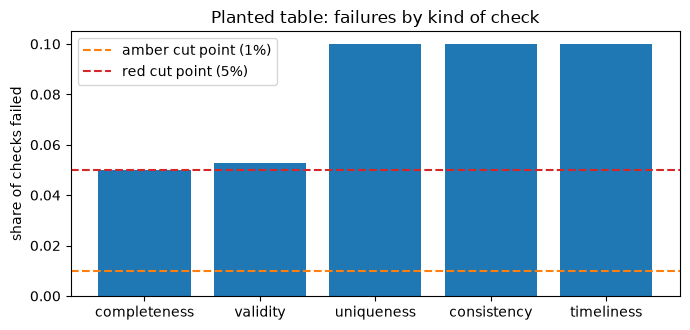

In [11]:
# Share of failed checks per kind of check, against the amber and red cut points of the policy
shares = [c.n_failed / c.n_checked for c in counts]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(CHECK_NAMES, shares, color="tab:blue")
ax.axhline(0.01, color="tab:orange", linestyle="--", label="amber cut point (1%)")
ax.axhline(0.05, color="tab:red", linestyle="--", label="red cut point (5%)")
ax.set_ylabel("share of checks failed")
ax.set_title("Planted table: failures by kind of check")
ax.legend()
fig.tight_layout()
plt.show()

The bars are the share of checks that failed for each kind, and both dashed lines are the cut points of the
policy. All five kinds sit at or above the red line: 0.0500 of the cells are missing, 0.0526 of the range checks fail,
and the three row-level kinds fail at 0.1000. The test reads the **largest** share, which is why the light is red with
0.1000, however well the other kinds do. The table was built with exactly one defect of each kind, so the figure shows
how a light is read, not how common each defect is in a real portfolio, where one kind usually dominates.

### Step 7: the committed screen on the real model

The variant of case C20 ran the same four screens on a LightGBM model with 30,000 Taiwan cards, once with the planted feature and once on the clean control. The next cell lists the two `ml.leakage_screen` rows the pipeline wrote, with the engine version that produced them (the pipeline calls the same function this notebook called).

In [12]:
# The two committed ml.leakage_screen rows: the model with the planted feature and the clean control
rows = [t for t in variant["tests"] if t["test_id"] == "ml.leakage_screen"]
print("rows:", len(rows), "| baked with riskvalidation", variant["provenance"]["riskvalidation_version"])
for t in rows:
    print(
        f"{t['model_id']:34s} light: {LIGHT[t['light']]:6s} screens tripped: {int(t['statistic'])} | n {t['n']}"
    )
    for name, s in t["extras"]["screens"].items():
        print(f"    {SCREEN[name]:12s} value {s['value']:.4f} light: {LIGHT[s['light']]}")

rows: 2 | baked with riskvalidation 1.0.1
P4-lightgbm-taiwan-planted-leak    light: red    screens tripped: 2 | n 30000
    temporal     value 9000.0000 light: red
    single       value 0.9998 light: red
    overlap      value 0.0000 light: green
    resemblance  value 0.4932 light: green
P4-lightgbm-taiwan                 light: green  screens tripped: 0 | n 30000
    temporal     value 0.0000 light: green
    single       value 0.6833 light: green
    overlap      value 0.0000 light: green
    resemblance  value 0.4986 light: green


### Step 8: the evidence, drawn

The last cell draws, for the two engine samples, the AUC of each column against the 0.95 line, and for the committed variant the AUC of the model on the development sample against decision time. The leak is invisible in the first number and obvious in the drop to the second.

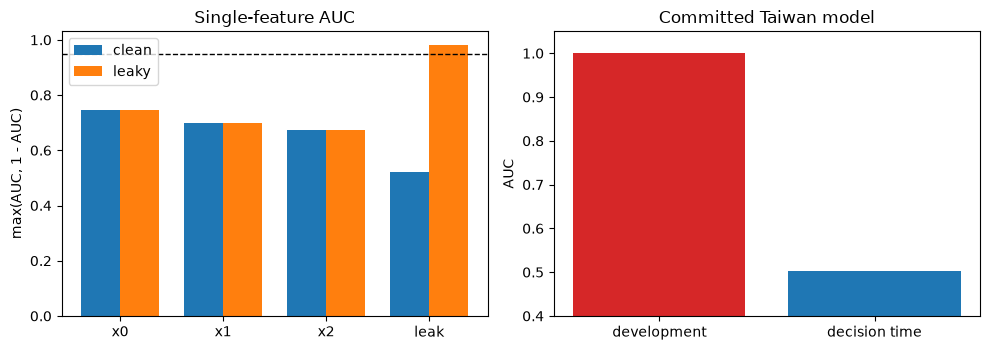

In [13]:
# Left: AUC of every column with the 0.95 cut point; right: development against decision-time AUC
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
width = 0.38
for k, (label, (X, y, _)) in enumerate(samples.items()):
    aucs = [float(disc.disc_auc(X[:, j], y).metric) for j in range(X.shape[1])]
    folded = [max(a, 1 - a) for a in aucs]
    left.bar(np.arange(len(folded)) + (k - 0.5) * width, folded, width=width, label=label)
left.axhline(0.95, color="black", linestyle="--", linewidth=1)
left.set_xticks(range(4))
left.set_xticklabels(["x0", "x1", "x2", "leak"])
left.set_ylabel("max(AUC, 1 - AUC)")
left.set_title("Single-feature AUC")
left.legend(loc="upper left")
right.bar(
    ["development", "decision time"],
    [perf["development_auc"], perf["decision_time_auc"]],
    color=["tab:red", "tab:blue"],
)
right.set_ylim(0.4, 1.05)
right.set_ylabel("AUC")
right.set_title("Committed Taiwan model")
fig.tight_layout()
plt.show()

## Results

**Answer:** Not on the leaky sample, and yes on the clean one, and the screens say which. The single-feature AUC reads 0.9818 on the leaky sample against 0.7454 on the clean one, which turns the light red. On the committed Taiwan model the planted `future_status_code` lifts the AUC to 0.9997 on the development sample and it falls to 0.5028 at decision time, while the screen read 0.9998 on the feature. The planted data table fails 5 of 69 checked cells or rows, with a worst share of 0.1000: red.

- **A clean sample passes and an honest strong feature is not a leak.** The clean sample trips none of the four screens. Its best column ranks the defaulters with an AUC of 0.7454, well under the 0.95 line, which is what real credit information looks like.
- **The planted leak is found by the screen that is built to find it, and only by that one.** On the leaky sample the single-feature AUC is 0.9818 (the exact value for strength 3 is 0.9831, the difference is sampling noise) and the light is red with one screen tripped. The temporal order, the overlap and the resemblance stay green, because this leak sits in the value of a feature and says nothing about dates, entities or populations.
- **The resemblance screen has limited reach.** On the engine's shift plant it reads 0.5058 without shift and 0.6109 with a shift of 1.5 standard deviations on a quarter of the rows. Both are under the 0.70 cut point: the screen is green on a population that did move. It is a screen for large differences between the development and the out-of-time sample, and a reader should not take green as "the samples are alike".
- **Data quality is a count, and the largest share decides.** The planted table fails 5 of the 69 cells or rows checked and its worst share is 0.1000 (a repeated identifier, a disagreeing view and a stale date at 1 in 10), so the light is red; the repaired copy fails none and is green. The cut points (1% and 5%) are conventions.
- **The committed C20 variant agrees.** On the Taiwan model the planted `future_status_code` trips two screens: 9,000 feature values dated after the observation date and a single-feature AUC of 0.9998. The clean control trips none (its best single feature is 0.6833). The model with the leak scores an AUC of 0.9997 on the development sample and 0.5028 at decision time, when the leak is not available. The rows were baked with riskvalidation 1.0.1, the version installed here.

What the screens do not show: they find the leak forms they were built for. A leak spread over several honest-looking features, or a feature that is legitimately dated but caused by the outcome, passes all four. A green screen is the absence of these findings, never a proof that the sample is fit. The planted leaks are synthetic, and the cut points are conventions, not regulatory thresholds.

## Summary

- A validator reads the sample before the model: a feature that carries the answer makes every later performance number flattering.
- The engine has four leakage screens: the temporal order and the entity overlap are rules (one violation is a leak), the single-feature AUC (above 0.95) and the cross-fitted resemblance AUC (above 0.70) have cut points; `leakage_screen` takes the worst light of the four and counts the ones that tripped.
- Each screen finds one form of leak and is blind to the others, so the four run together and a green result is an absence of findings.
- Data quality is five counted checks (completeness, validity, uniqueness, consistency, timeliness); the light follows the largest share of failures.
- The committed C20 variant is the same logic on a real model: the planted feature trips two screens, the clean control none, and the AUC falls from 0.9997 to 0.5028 when the leak is gone.

**What to try next.** Notebook 02 of this topic stresses a model the sample has already passed: input noise, shift and overfitting. Then topic 14 measures how often tests like these catch a planted defect and how often they fire on a right model.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (the AUC and its variance). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- ING (2026), probatus, `sample_similarity`: a resemblance model between two datasets. https://github.com/ing-bank/probatus
- EBA (2023), Follow-up report on machine learning for IRB models, EBA/REP/2023/28. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2023/1061483/Follow-up%20report%20on%20machine%20learning%20for%20IRB%20models.pdf
- Yeh, I-C. and Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), the Taiwan cards of the C20 variants. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients